# Behavioural sensitivity of heat exposure

Which **behavioural** assumptions drive the model's heat-exposure results? Geography (street network, heat rasters, population, amenities) and the transit service (GTFS routes and schedules) are held fixed; only how people behave is varied.

**Main results** use the current, survey-calibrated parameters: `01_nairobi_heat_abm.ipynb`. This notebook reads the batch written by

```
python -m nairobi_heat_abm.rdm.run_sensitivity        # settings: config.yaml -> sensitivity
```

**Model.** Every agent makes a round trip: out from home and back. Exposure is **°C·min of UTCI above 26 °C**, summed over the day's outdoor minutes (walking and waiting); minutes at or below 26 °C add nothing.

**Method: Morris elementary effects.** Each trajectory starts at a random point on a 4-level grid over the factor ranges and changes one factor at a time by 2/3 of its range, so *k* factors cost *k* + 1 runs per trajectory. All runs in a trajectory share a seed, and the model draws each component (homes, purposes, departure times, destinations, walking speeds, boarding waits, return times) from its own random stream, so one step changes only what that factor touches. The difference between consecutive runs is the factor's **elementary effect** (EE), scaled here to the factor's full range: roughly *the change in the outcome from moving the factor from the low to the high end of its range*.

- **μ\*** = mean |EE|: importance. Ranks the factors.
- **μ** = mean EE: direction (positive = raising the factor raises the outcome).
- **σ** = SD of EE: large relative to μ\* means the effect depends on where the other factors are (non-linearity or interactions).

Baseline replicates at the survey parameters with different seeds show how much outcomes move from agent sampling alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

from nairobi_heat_abm.rdm.sensitivity import OUTCOMES

cfg = yaml.safe_load((ROOT / "config.yaml").read_text())
OUT = ROOT / cfg["sensitivity"].get("output_dir", "outputs/sensitivity")
factors = pd.read_csv(OUT / "factors.csv")
design = pd.read_csv(OUT / "design.csv")
runs = pd.read_csv(OUT / "runs.csv")
indices = pd.read_csv(OUT / "morris_indices.csv")
settings = json.loads((OUT / "run_config.json").read_text())
LABEL = dict(zip(factors["factor"], factors["label"]))

n_morris = (runs["kind"] == "morris").sum()
print(f"{settings['n_agents']:,} agents per run; {len(runs)} of {len(design)} runs finished "
      f"({(runs['kind'] == 'baseline').sum()} baseline replicates, {n_morris} Morris runs, "
      f"{settings['trajectories']} trajectories x {len(factors) + 1})")
print(f"Total run time {runs['seconds'].sum() / 3600:.1f} h")

3,000 agents per run; 185 of 185 runs finished (5 baseline replicates, 180 Morris runs, 10 trajectories x 18)
Total run time 7.3 h


## Factors varied

Ranges for survey-calibrated factors span the survey's own sub-group fits; the others are assumptions with a plausible range around the model default.

**Behavioural parameters not varied, and why:**
- `trip_rate_mean/std`: the model simulates one round trip per agent (out and home), so the trip rate is only reported, never simulated.
- `min_stay_min` and `dwell_sigma_log` (return-trip timing): the means and medians of the trip home are varied instead.
- `travel_probability`: scales *who* travels, not the exposure of those who do (all outcomes here are per traveller).
- `transit_wait_tolerance_std`: not used by the router (only the mean tolerance is).
- Demographic modifiers: all neutral by default, except children's school departure window, which is a hard school-start rule.

In [2]:
display(factors.set_index("factor")[["label", "low", "baseline", "high", "source"]])

,label,low,baseline,high,source
factor,,,,,
destination_distance_decay,Destination distance decay (exponent),1.10,1.50,1.90,WRI rider survey Q11 median ride time (calibra...
walk_time_weight,Walking-time weight in route choice (x riding),2.00,5.00,6.00,WRI rider survey Q8 access times (calibration....
walk_share_shift_pp,Walk share vs. JICA distance curves (+- pct po...,-15.00,0.00,15.00,JICA 2014 Nairobi walk-split curves (2013 pers...
walk_speed_mean_mps,"Walking speed, mean (m/s)",1.00,1.20,1.40,literature default
walk_speed_std_mps,"Walking speed, SD between people (m/s)",0.05,0.15,0.30,assumption
transit_mean_wait_min,Mean boarding wait (min),4.50,5.65,7.00,"WRI rider survey Q15; bus 5.1, matatu 6.7, 06-..."
transit_wait_tolerance_min,Wait tolerance before walking instead (min),5.00,15.00,30.00,assumption
peak1_hour,Morning outbound departure peak (hour),6.50,7.40,8.50,assumption; refit for round trips (departure_f...
peak1_weight,Share of outbound trips in morning peak,0.50,0.66,0.80,assumption; refit for round trips (departure_f...


## Baseline: the survey parameters, replicated over seeds

Mean and SD across the baseline replicates. The SD is the sampling noise of one run at this agent count. An effect much smaller than it shouldn't be read much into; the Morris differences themselves are less noisy than this, because each step shares its seed with the previous run.

In [3]:
base = pd.read_csv(OUT / "baseline_summary.csv").set_index("outcome")
base.insert(0, "description", [OUTCOMES.get(o, o) for o in base.index])
display(base.round(2))

,description,mean,std,count,cv
outcome,,,,,
mean_exposure,Mean exposure per traveller (°C·min),310.90,5.78,5.0,0.02
median_exposure,Median exposure per traveller (°C·min),197.09,2.62,5.0,0.01
p90_exposure,90th-percentile exposure (°C·min),689.27,12.64,5.0,0.02
mean_outdoor_min,Mean minutes outdoors per traveller,65.48,0.86,5.0,0.01
mean_temp_experienced,Mean UTCI while outdoors (°C),29.14,0.07,5.0,0.00
transit_trip_share,Share of trips using transit,0.55,0.01,5.0,0.02
walk_trip_mean_exposure,"Mean exposure, walk-only trips (°C·min)",334.13,12.46,5.0,0.04
transit_trip_mean_exposure,"Mean exposure, transit trips (°C·min)",291.93,5.07,5.0,0.02
rwi_gap,"Exposure gap, poorest − richest RWI quintile (...",63.56,33.70,5.0,0.53


## Which behaviours matter most for mean exposure?

Bars: μ\* with its 95% bootstrap interval across trajectories. The label gives the direction: ↑ raising the factor raises exposure, ↓ lowers it, ↕ mixed.

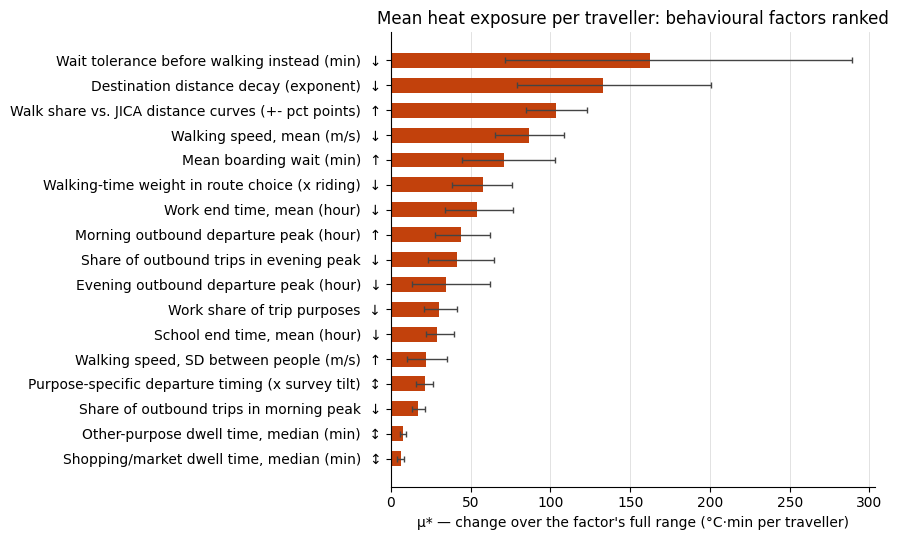

Seed-to-seed SD of mean exposure at baseline: 6 °C·min


,rank,factor,mu,mu_star,mu_star_lo,mu_star_hi,sigma
0,1,transit_wait_tolerance_min,-162.6,162.6,71.3,289.1,181.3
1,2,destination_distance_decay,-133.2,133.2,78.8,200.8,105.3
2,3,walk_share_shift_pp,103.5,103.5,84.6,122.7,33.3
3,4,walk_speed_mean_mps,-86.7,86.7,65.5,108.7,37.1
4,5,transit_mean_wait_min,71.0,71.0,44.5,103.2,48.8
5,6,walk_time_weight,-57.5,57.5,38.0,76.0,34.2
6,7,work_end_hour_mean,-54.1,54.1,33.7,76.5,36.8
7,8,peak1_hour,43.8,43.8,27.8,62.3,30.7
8,9,peak2_weight,-38.6,41.5,23.1,64.6,40.6
9,10,peak2_hour,-34.4,34.4,13.4,62.2,41.5


In [4]:
def direction(row):
    if abs(row["mu"]) >= 0.8 * row["mu_star"]:
        return "↑" if row["mu"] > 0 else "↓"
    return "↕"

def plot_mu_star(outcome, ax, unit):
    d = indices[indices["outcome"] == outcome].sort_values("mu_star")
    y = np.arange(len(d))
    err = np.vstack([d["mu_star"] - d["mu_star_lo"], d["mu_star_hi"] - d["mu_star"]])
    ax.barh(y, d["mu_star"], color="#c2410c", height=0.6)
    ax.errorbar(d["mu_star"], y, xerr=err, fmt="none", ecolor="#444", elinewidth=1, capsize=2)
    ax.set_yticks(y, [f"{LABEL[f]}  {direction(r)}" for f, (_, r) in zip(d["factor"], d.iterrows())])
    ax.set_xlabel(f"μ* — change over the factor's full range ({unit})")
    ax.grid(axis="x", color="#ddd", linewidth=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_mu_star("mean_exposure", ax, "°C·min per traveller")
ax.set_title("Mean heat exposure per traveller: behavioural factors ranked")
plt.tight_layout(); plt.show()

sd = base.loc["mean_exposure", "std"]
print(f"Seed-to-seed SD of mean exposure at baseline: {sd:,.0f} °C·min")
display(indices[indices["outcome"] == "mean_exposure"][["rank", "factor", "mu", "mu_star", "mu_star_lo", "mu_star_hi", "sigma"]].round(1))

### Duration or temperature?

Exposure (°C·min above 26 °C) grows with minutes outdoors and with how hot those minutes are. The mean UTCI experienced here is raw UTCI (no threshold). Ranking the factors on each part separately shows whether a behaviour matters because it changes **how long** people are outside or **when/where** they are outside.

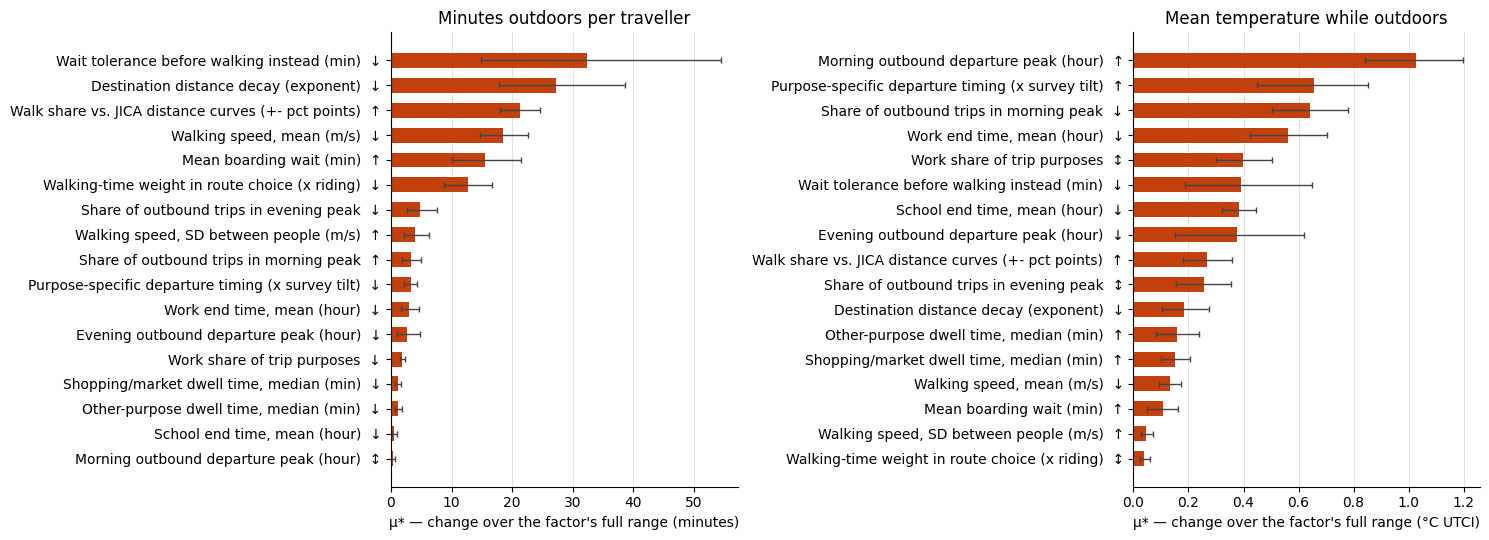

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_mu_star("mean_outdoor_min", axes[0], "minutes")
axes[0].set_title("Minutes outdoors per traveller")
plot_mu_star("mean_temp_experienced", axes[1], "°C UTCI")
axes[1].set_title("Mean temperature while outdoors")
plt.tight_layout(); plt.show()

### Importance vs. interaction (μ\* vs. σ)

Factors far to the right matter. Factors above the dashed line (σ > μ\*) have effects that depend strongly on the other factors' values.

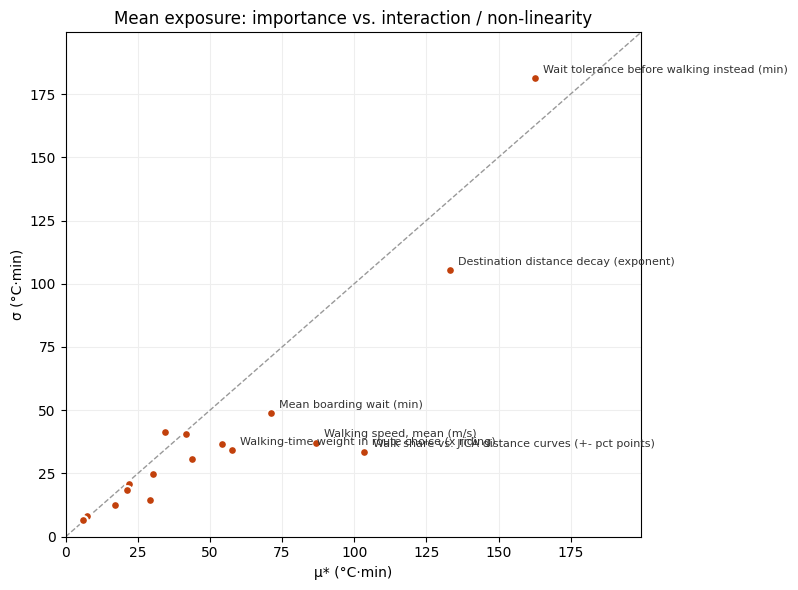

In [6]:
d = indices[indices["outcome"] == "mean_exposure"]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d["mu_star"], d["sigma"], s=40, color="#c2410c", edgecolor="white", linewidth=1.5, zorder=3)
for _, r in d.iterrows():
    if r["rank"] <= 6:
        ax.annotate(LABEL[r["factor"]], (r["mu_star"], r["sigma"]), textcoords="offset points", xytext=(6, 4), fontsize=8, color="#333")
lim = max(d["mu_star"].max(), d["sigma"].max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="#999", lw=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("μ* (°C·min)"); ax.set_ylabel("σ (°C·min)")
ax.set_title("Mean exposure: importance vs. interaction / non-linearity")
ax.grid(color="#eee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## All outcomes at a glance

μ\* of each factor as a share of the most important factor **for that outcome** (1.0 = top factor). Read across a row to see which outcomes a behaviour drives. The socioeconomic gaps (poorest − richest wealth quintile; medium/high − low informality) are differences of group means, so they are much noisier than the city-wide means. Compare their μ\* with the baseline SD above before interpreting them.

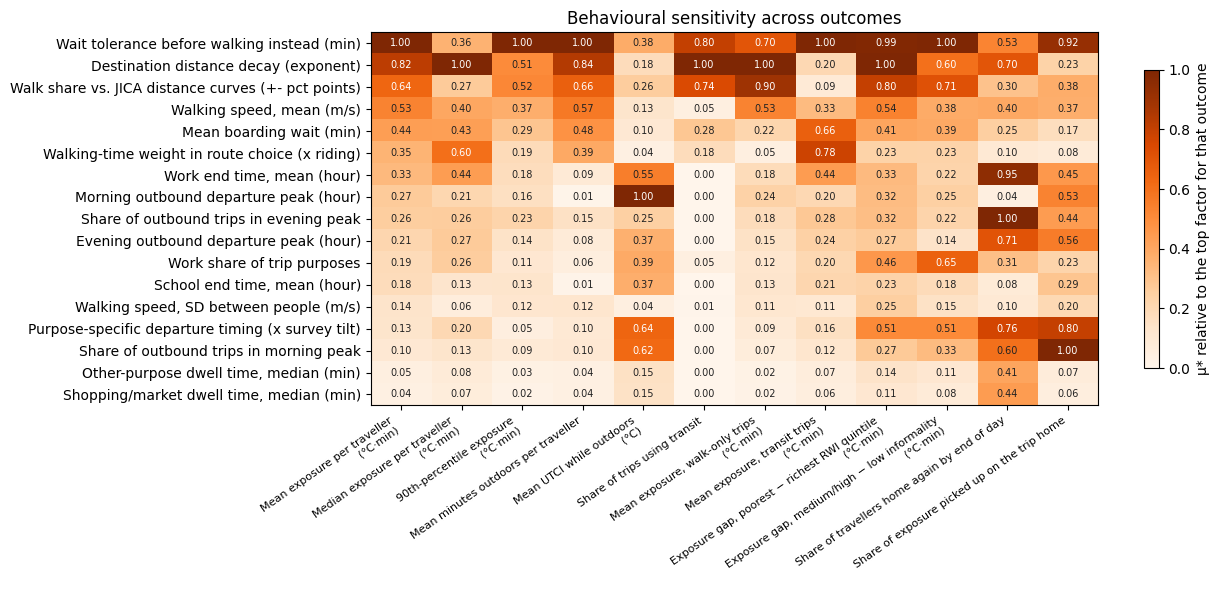

In [7]:
share = indices.assign(rel=indices["mu_star"] / indices.groupby("outcome")["mu_star"].transform("max"))
mat = share.pivot(index="factor", columns="outcome", values="rel")
mat = mat.loc[indices[indices["outcome"] == "mean_exposure"].sort_values("rank")["factor"], [o for o in OUTCOMES if o in mat.columns]]

fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(mat.to_numpy(), cmap="Oranges", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(mat)), [LABEL[f] for f in mat.index])
ax.set_xticks(range(mat.shape[1]), [OUTCOMES[o].replace(" (", "\n(") for o in mat.columns], rotation=35, ha="right", fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#222")
fig.colorbar(im, ax=ax, label="μ* relative to the top factor for that outcome", shrink=0.8)
ax.set_title("Behavioural sensitivity across outcomes")
plt.tight_layout(); plt.show()

In [8]:
print("μ* (outcome units) for every outcome and factor:")
display(indices.pivot(index="factor", columns="outcome", values="mu_star")[list(mat.columns)].loc[mat.index].round(2))

μ* (outcome units) for every outcome and factor:


outcome,mean_exposure,median_exposure,p90_exposure,mean_outdoor_min,mean_temp_experienced,transit_trip_share,walk_trip_mean_exposure,transit_trip_mean_exposure,rwi_gap,informality_gap,returned_share,return_exposure_share
factor,,,,,,,,,,,,
transit_wait_tolerance_min,162.65,38.91,577.89,32.41,0.39,0.18,165.57,148.44,30.09,22.53,0.04,0.07
destination_distance_decay,133.21,109.28,293.36,27.24,0.18,0.23,237.05,29.80,30.46,13.55,0.05,0.02
walk_share_shift_pp,103.47,29.35,299.90,21.36,0.27,0.17,212.25,13.19,24.34,16.03,0.02,0.03
walk_speed_mean_mps,86.74,43.58,216.22,18.48,0.13,0.01,126.48,48.29,16.38,8.67,0.03,0.03
transit_mean_wait_min,71.00,46.97,169.28,15.54,0.11,0.06,51.11,97.94,12.45,8.85,0.02,0.01
walk_time_weight,57.51,66.00,107.20,12.72,0.04,0.04,10.91,115.90,7.10,5.14,0.01,0.01
work_end_hour_mean,54.09,48.03,101.36,2.98,0.56,0.00,43.04,65.90,10.11,5.04,0.07,0.04
peak1_hour,43.83,22.81,92.36,0.33,1.03,0.00,55.92,30.09,9.76,5.59,0.00,0.04
peak2_weight,41.53,28.51,130.33,4.82,0.26,0.00,41.80,41.53,9.62,5.03,0.07,0.04


## Caveats

- **Morris is a screening method.** μ\* ranks factors reliably with ~10 trajectories, but it is not a variance decomposition. If two or three factors dominate, a follow-up variance-based (Sobol) analysis on just those would quantify their shares and interactions.
- **Ranges drive rankings.** A factor with a wide assumed range can outrank a more uncertain factor that was given a narrow one. Change ranges in `config.yaml` → `sensitivity.ranges`, then rerun to a new `output_dir`.
- **Agent count.** Runs use fewer agents than the main notebook (`sensitivity.n_agents`). Use the baseline SD as the noise floor.
- Outcomes inherit every limitation of the main model (one round trip per agent, so no trip chains or second trips; the outbound departure profile is an assumption refit for round trips; walking speed doesn't respond to heat).